# Original Implementation

---

In [1]:
#=========
# Imports
#=========

import time
import csv
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
#=================================
# Configuration & Reproducibility
#=================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Training configuration
EPOCHS = 400
LEARNING_RATE = 0.01
BATCH_SIZE = 32  # Defined by the author, but not used in training.

# Dataset configuration
TEST_SIZE = 0.2

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
#=============
# Data Loading
#=============

def load_csv(filename):
    lines = []

    with open(filename) as csvfile:
        reader = csv.DictReader(csvfile)

        for line in reader:
            lines.append(line)

    return lines

In [4]:
#=============
# Load Dataset
#=============

DATA_PATH = "data/healthcare-dataset-stroke-data.csv"

data = load_csv(DATA_PATH)

In [5]:
#================
# Data Inspection
#=================

print(f"Number of records: {len(data)}")
print(f"Number of features: {len(data[0])}")

print("\nColumn names:")
print(list(data[0].keys()))

print("\nFirst record:")
print(data[0])

Number of records: 5110
Number of features: 12

Column names:
['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']

First record:
{'id': '9046', 'gender': 'Male', 'age': '67', 'hypertension': '0', 'heart_disease': '1', 'ever_married': 'Yes', 'work_type': 'Private', 'Residence_type': 'Urban', 'avg_glucose_level': '228.69', 'bmi': '36.6', 'smoking_status': 'formerly smoked', 'stroke': '1'}


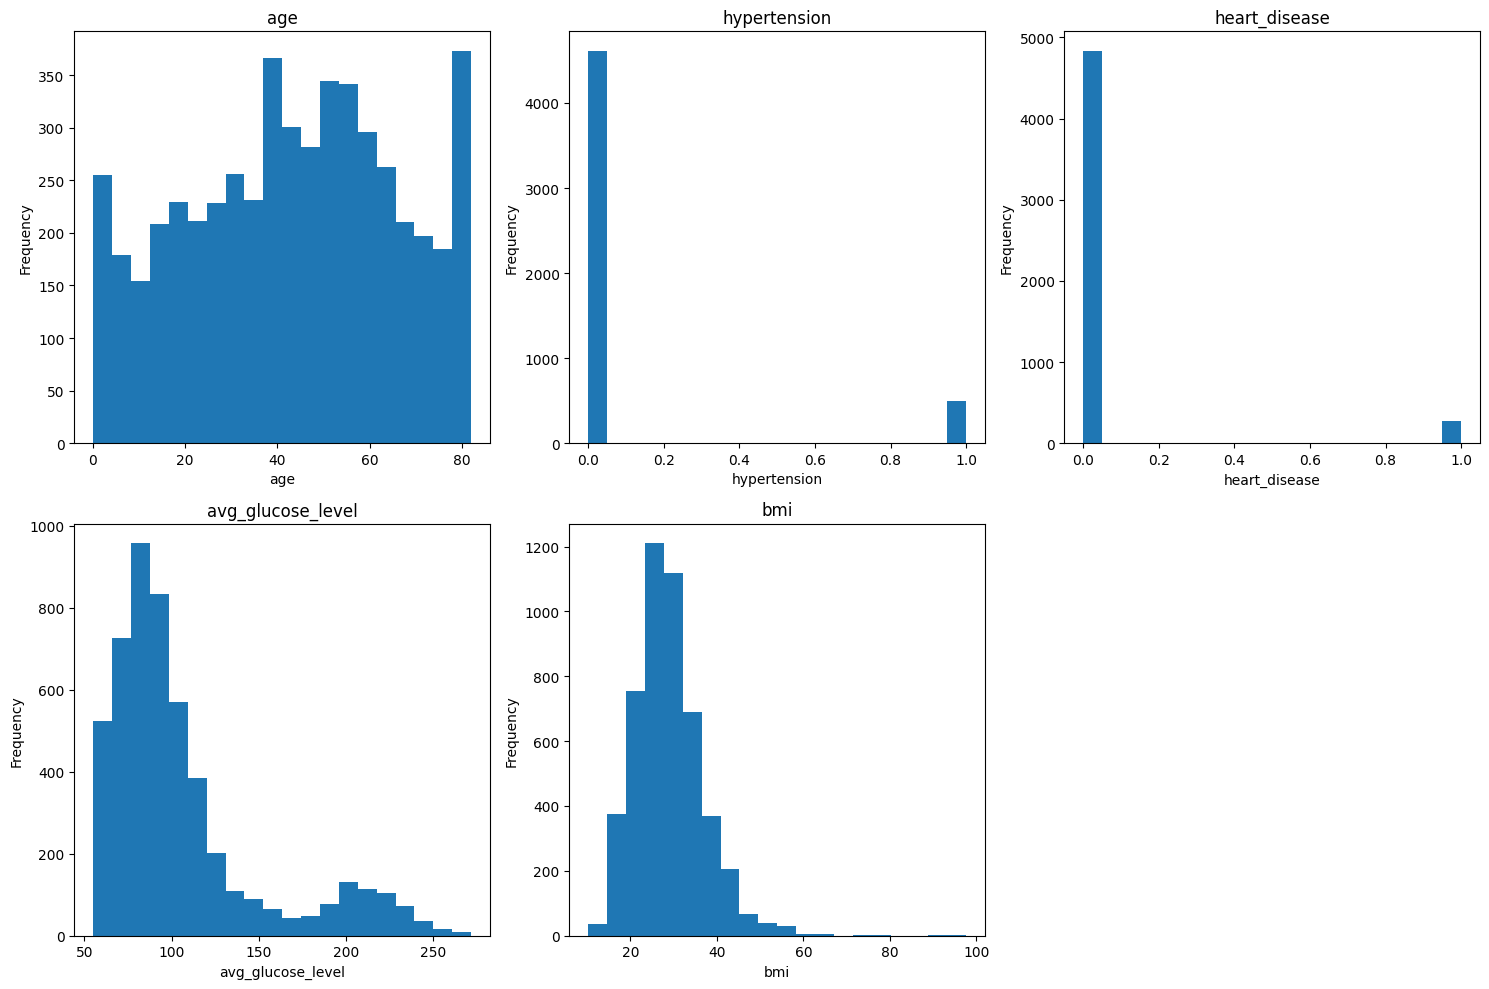

In [6]:
#==========================
# Exploratory Data Analysis
#==========================

numerical_features = [
    key for key in data[0].keys()
    if key not in [
        'id',
        'gender',
        'ever_married',
        'work_type',
        'Residence_type',
        'smoking_status',
        'stroke'
    ]
]

num_plots = len(numerical_features)
num_cols = 3
num_rows = (num_plots + num_cols - 1) // num_cols

fig, axes = plt.subplots(
    num_rows,
    num_cols,
    figsize=(15, 5 * num_rows)
)

axes = axes.flatten()

for i, feature in enumerate(numerical_features):
    try:
        values = [
            float(item[feature])
            for item in data
            if item[feature] != 'N/A'
        ]

        axes[i].hist(values, bins=20)
        axes[i].set_title(feature)
        axes[i].set_xlabel(feature)
        axes[i].set_ylabel("Frequency")

    except (ValueError, TypeError):
        print(f"Skipping {feature} due to non-numeric or invalid values")

    except IndexError:
        pass

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

In [7]:
#===================
# Data Preprocessing
#===================

df = pd.read_csv(DATA_PATH)

# Handle missing values
df['bmi'] = df['bmi'].fillna(df['bmi'].mean())
df['smoking_status'] = df['smoking_status'].fillna(
    df['smoking_status'].mode()[0]
)

# Encode categorical features
label_encoders = {}

categorical_cols = [
    'gender',
    'ever_married',
    'work_type',
    'Residence_type',
    'smoking_status'
]

for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le

# Separate features and target
X = df.drop(['stroke', 'id'], axis=1)
y = df['stroke']

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=SEED
)

# Standardize numerical features
numerical_cols = [
    'age',
    'hypertension',
    'heart_disease',
    'avg_glucose_level',
    'bmi'
]

scaler = StandardScaler()

X_train[numerical_cols] = scaler.fit_transform(
    X_train[numerical_cols]
)

X_test[numerical_cols] = scaler.transform(
    X_test[numerical_cols]
)

In [8]:
#================
# PyTorch Tensors
#================

X_train_tensor = torch.tensor(
    X_train.values,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train.values,
    dtype=torch.long
)

X_test_tensor = torch.tensor(
    X_test.values,
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test.values,
    dtype=torch.long
)

# Dataset information
print("Dataset Information:")
print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")
print(f"Number of features: {X_train.shape[1]}")

print("\nClass distribution in training set:")
print(y_train.value_counts(normalize=True))

Dataset Information:
Training samples: 4088
Testing samples: 1022
Number of features: 10

Class distribution in training set:
stroke
0    0.954256
1    0.045744
Name: proportion, dtype: float64


In [9]:
#===================
# Model Architecture
#===================

class DenseNN(nn.Module):

    def __init__(self, input_size, num_classes):
        super(DenseNN, self).__init__()

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(input_size, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 32)
        self.fc4 = nn.Linear(32, num_classes)

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3)

        self.batch_norm1 = nn.BatchNorm1d(128)
        self.batch_norm2 = nn.BatchNorm1d(64)
        self.batch_norm3 = nn.BatchNorm1d(32)

    def forward(self, x):

        x = self.flatten(x)

        x = self.relu(self.batch_norm1(self.fc1(x)))
        x = self.dropout(x)

        x = self.relu(self.batch_norm2(self.fc2(x)))
        x = self.dropout(x)

        x = self.relu(self.batch_norm3(self.fc3(x)))

        x = self.fc4(x)

        return x

In [10]:
#================
# Model Training
#================

def train_model(model, X_train_tensor, y_train_tensor, config):

    # Calculate class weights
    class_counts = torch.bincount(y_train_tensor)
    total_samples = len(y_train_tensor)

    class_weights = total_samples / (2 * class_counts)
    class_weights = class_weights / class_weights.sum()

    criterion = nn.CrossEntropyLoss(weight=class_weights)

    optimizer = optim.Adam(
        model.parameters(),
        lr=config['learning_rate']
    )

    history = {
        'train_loss': [],
        'train_accuracy': [],
        'train_f1': []
    }

    for epoch in range(config['num_epochs']):

        model.train()

        # Forward pass
        optimizer.zero_grad()

        train_outputs = model(X_train_tensor)
        loss = criterion(train_outputs, y_train_tensor)

        # Training predictions
        train_preds = torch.argmax(train_outputs, dim=1)

        train_acc = accuracy_score(
            y_train_tensor.numpy(),
            train_preds.numpy()
        )

        train_f1 = f1_score(
            y_train_tensor.numpy(),
            train_preds.numpy()
        )

        # Backpropagation and optimization
        loss.backward()
        optimizer.step()

        # Record metrics
        history['train_loss'].append(loss.item())
        history['train_accuracy'].append(train_acc)
        history['train_f1'].append(train_f1)

        if (epoch + 1) % 2 == 0:
            print(
                f"Epoch [{epoch + 1}/{config['num_epochs']}], "
                f"Loss: {loss.item():.4f}, "
                f"Train Acc: {train_acc:.4f}, "
                f"Train F1: {train_f1:.4f}"
            )

    return history

In [11]:
#================
# Model Configuration & Training
#================

config = {
    'num_epochs': EPOCHS,
    'learning_rate': LEARNING_RATE,
    'batch_size': BATCH_SIZE,
    'dropout_rate': 0.3,
    'hidden_sizes': [128, 64, 32]
}

input_size = X_train.shape[1]
num_classes = 2

# Initialize model
model = DenseNN(input_size, num_classes)

# Train model
start_time = time.time()

history = train_model(
    model,
    X_train_tensor,
    y_train_tensor,
    config
)

training_time = time.time() - start_time

print(f"\nTraining Time: {training_time:.2f} seconds")

Epoch [2/400], Loss: 0.5763, Train Acc: 0.6964, Train F1: 0.1894
Epoch [4/400], Loss: 0.5452, Train Acc: 0.6270, Train F1: 0.1788
Epoch [6/400], Loss: 0.5111, Train Acc: 0.6522, Train F1: 0.1884
Epoch [8/400], Loss: 0.4968, Train Acc: 0.6925, Train F1: 0.2029
Epoch [10/400], Loss: 0.4847, Train Acc: 0.7114, Train F1: 0.2102
Epoch [12/400], Loss: 0.4740, Train Acc: 0.7194, Train F1: 0.2160
Epoch [14/400], Loss: 0.4629, Train Acc: 0.7138, Train F1: 0.2200
Epoch [16/400], Loss: 0.4773, Train Acc: 0.6964, Train F1: 0.2060
Epoch [18/400], Loss: 0.4686, Train Acc: 0.6910, Train F1: 0.2062
Epoch [20/400], Loss: 0.4433, Train Acc: 0.6972, Train F1: 0.2115
Epoch [22/400], Loss: 0.4445, Train Acc: 0.7057, Train F1: 0.2111
Epoch [24/400], Loss: 0.4407, Train Acc: 0.7084, Train F1: 0.2158
Epoch [26/400], Loss: 0.4380, Train Acc: 0.7231, Train F1: 0.2278
Epoch [28/400], Loss: 0.4386, Train Acc: 0.7282, Train F1: 0.2258
Epoch [30/400], Loss: 0.4481, Train Acc: 0.7219, Train F1: 0.2196
Epoch [32/400]

In [12]:
#================
# Final Model Evaluation
#================

model.eval()

with torch.no_grad():
    test_outputs = model(X_test_tensor)
    y_pred = torch.argmax(test_outputs, dim=1)

y_pred = y_pred.numpy()
y_true = y_test_tensor.numpy()

# Calculate metrics
metrics = {
    'accuracy': accuracy_score(y_true, y_pred),
    'precision': precision_score(y_true, y_pred),
    'recall': recall_score(y_true, y_pred),
    'f1_score': f1_score(y_true, y_pred),
    'confusion_matrix': confusion_matrix(y_true, y_pred)
}

# Display results
print("Dense Neural Network — Final Results")
print("-" * 40)

print(f"Accuracy:  {metrics['accuracy']:.4f}")
print(f"Precision: {metrics['precision']:.4f}")
print(f"Recall:    {metrics['recall']:.4f}")
print(f"F1 Score:  {metrics['f1_score']:.4f}")

print("\nConfusion Matrix:")
print(metrics['confusion_matrix'])

print("\nClassification Report:")
print(classification_report(y_true, y_pred))

Dense Neural Network — Final Results
----------------------------------------
Accuracy:  0.8571
Precision: 0.2042
Recall:    0.4677
F1 Score:  0.2843

Confusion Matrix:
[[847 113]
 [ 33  29]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.88      0.92       960
           1       0.20      0.47      0.28        62

    accuracy                           0.86      1022
   macro avg       0.58      0.68      0.60      1022
weighted avg       0.92      0.86      0.88      1022



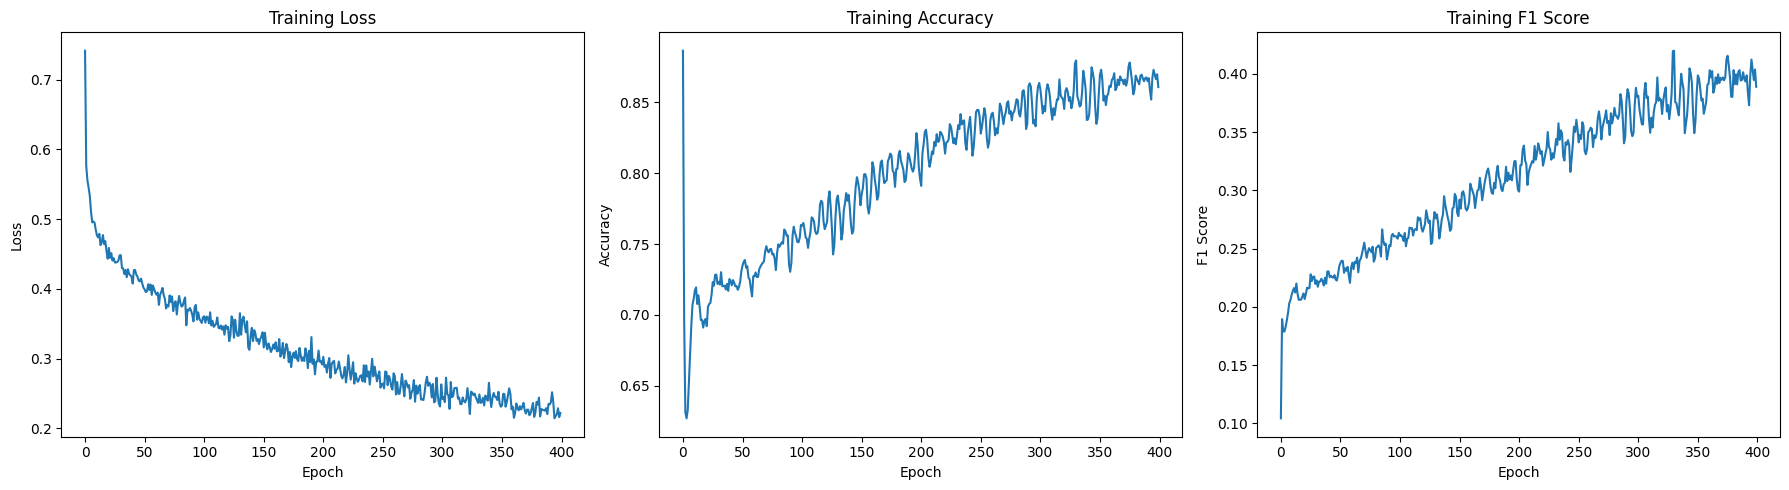

In [13]:
#================
# Training History Visualization
#================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Training loss
axes[0].plot(history['train_loss'])
axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")

# Training accuracy
axes[1].plot(history['train_accuracy'])
axes[1].set_title("Training Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")

# Training F1 score
axes[2].plot(history['train_f1'])
axes[2].set_title("Training F1 Score")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("F1 Score")

plt.tight_layout()
plt.show()

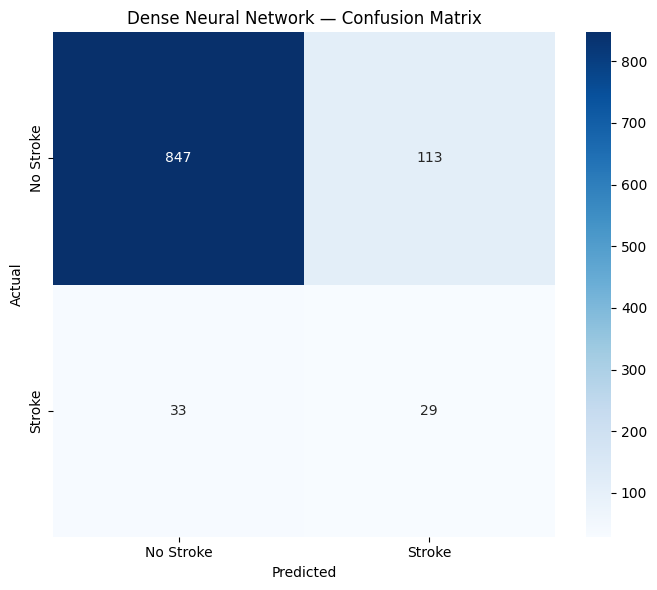

In [14]:
#================
# Confusion Matrix Visualization
#================

plt.figure(figsize=(7, 6))

sns.heatmap(
    metrics['confusion_matrix'],
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Stroke', 'Stroke'],
    yticklabels=['No Stroke', 'Stroke']
)

plt.title("Dense Neural Network — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

# Bonus: Modified Model on the Paper's Stroke Dataset

Everything above is the paper's implementation and is left untouched. This section applies the **modified architecture from our cardiovascular project** to the **paper's own dataset** (healthcare stroke data), which is what the bonus guidelines require before claiming anything about beating the paper.

**Only the model changes.** Everything else is the paper's pipeline, reused as is (same variables, same functions):

| Component | Original (paper) | Modified (this section) |
|---|---|---|
| Data, preprocessing, 80/20 split (`random_state=42`), scaling | paper cells above | **identical** (same tensors) |
| Loss | class-weighted cross-entropy inside `train_model` | **identical** (same `train_model` function) |
| Optimiser / learning rate / epochs / batch mode | Adam, `0.01`, 400, full-batch | **identical** (same `config` object) |
| Evaluation | final-epoch model on the test set, `argmax` | **identical** |
| Architecture | `DenseNN`: 128-64-32, BatchNorm, dropout 0.3 (after layers 1-2) | `ConfigurableMLP`: 32-16, BatchNorm, ReLU, dropout 0.1 |

**What is deliberately *not* carried over from the cardiovascular project**
* The engineered features (BMI, pulse pressure, blood-pressure stage, ...) are specific to the cardiovascular columns and do not exist in the stroke data.
* The mini-batch AdamW recipe with early stopping is a training-recipe change. Applying it here would change more than the model and break the like-for-like comparison.

**No tuning on this dataset.** The 32-16 architecture was selected earlier using the cardiovascular *validation* set. Nothing is tuned on the stroke data, and the paper's pipeline has no validation split, so the stroke test set is used only for the final report (single evaluation cell below).

**Seeds.** As the guidelines require, both models are trained 3 times (`42, 123, 2024`) on the same split. Seeds change only initialisation and dropout. The split stays fixed.

In [15]:
#================
# Bonus Setup
#================
import io
import contextlib
from sklearn.metrics import roc_auc_score, roc_curve

FINAL_SEEDS = [42, 123, 2024]


def set_seed(seed):
    # Same three calls as the paper's "Configuration & Reproducibility" cell
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def predict(net, X):
    # Same prediction rule as the paper: argmax over the two logits
    net.eval()
    with torch.no_grad():
        logits = net(X)
    pred = torch.argmax(logits, dim=1).numpy()
    prob = torch.softmax(logits, dim=1)[:, 1].numpy()
    return pred, prob


def count_params(net):
    return sum(p.numel() for p in net.parameters() if p.requires_grad)

In [16]:
#===========================================
# Modified Architecture (same as the cardiovascular project)
#===========================================
class ConfigurableMLP(nn.Module):
    # Hidden stack of Linear -> BatchNorm -> ReLU -> Dropout blocks
    def __init__(self, input_dim, hidden=(32, 16), dropout=0.1,
                 activation=nn.ReLU, norm="batch", num_classes=2):
        super().__init__()
        layers, prev = [], input_dim
        for h in hidden:
            layers.append(nn.Linear(prev, h))
            layers.append(nn.BatchNorm1d(h) if norm == "batch" else nn.LayerNorm(h))
            layers.append(activation())
            layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, num_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


MODEL_BUILDERS = {
    "Original DenseNN": lambda: DenseNN(input_size, num_classes),
    "Modified MLP": lambda: ConfigurableMLP(input_size, hidden=(32, 16), dropout=0.1, num_classes=num_classes),
}

print("Trainable parameters")
for name, build in MODEL_BUILDERS.items():
    print(f"  {name:18s}: {count_params(build()):,}")
print("\nModified architecture:")
print(MODEL_BUILDERS["Modified MLP"]())

Trainable parameters
  Original DenseNN  : 12,258
  Modified MLP      : 1,010

Modified architecture:
ConfigurableMLP(
  (network): Sequential(
    (0): Linear(in_features=10, out_features=32, bias=True)
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.1, inplace=False)
    (4): Linear(in_features=32, out_features=16, bias=True)
    (5): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.1, inplace=False)
    (8): Linear(in_features=16, out_features=2, bias=True)
  )
)


## Training: Original vs. Modified (3 seeds each)

Both models use the paper's `train_model` and the paper's `config` object, unchanged. The paper's function prints a line every 2 epochs; that output is suppressed here only to keep the notebook readable (6 runs × 400 epochs).

In [17]:
#================
# Train both models with 3 seeds (paper's train_model and config, unchanged)
#================
runs = {name: {} for name in MODEL_BUILDERS}

for seed in FINAL_SEEDS:
    for name, build in MODEL_BUILDERS.items():
        set_seed(seed)                     # same seeding point as in the paper: right before model creation
        net = build()

        start = time.time()
        with contextlib.redirect_stdout(io.StringIO()):
            hist = train_model(net, X_train_tensor, y_train_tensor, config)
        elapsed = time.time() - start

        runs[name][seed] = {"net": net, "history": hist}
        print(f"seed {seed} | {name:18s} | final train loss {hist['train_loss'][-1]:.4f} "
              f"| final train F1 {hist['train_f1'][-1]:.4f} | {elapsed:.1f}s")

seed 42 | Original DenseNN   | final train loss 0.2221 | final train F1 0.3888 | 11.2s
seed 42 | Modified MLP       | final train loss 0.3122 | final train F1 0.3475 | 3.7s
seed 123 | Original DenseNN   | final train loss 0.2244 | final train F1 0.3991 | 10.9s
seed 123 | Modified MLP       | final train loss 0.3015 | final train F1 0.3491 | 6.1s
seed 2024 | Original DenseNN   | final train loss 0.2149 | final train F1 0.4000 | 18.4s
seed 2024 | Modified MLP       | final train loss 0.2899 | final train F1 0.3185 | 3.7s


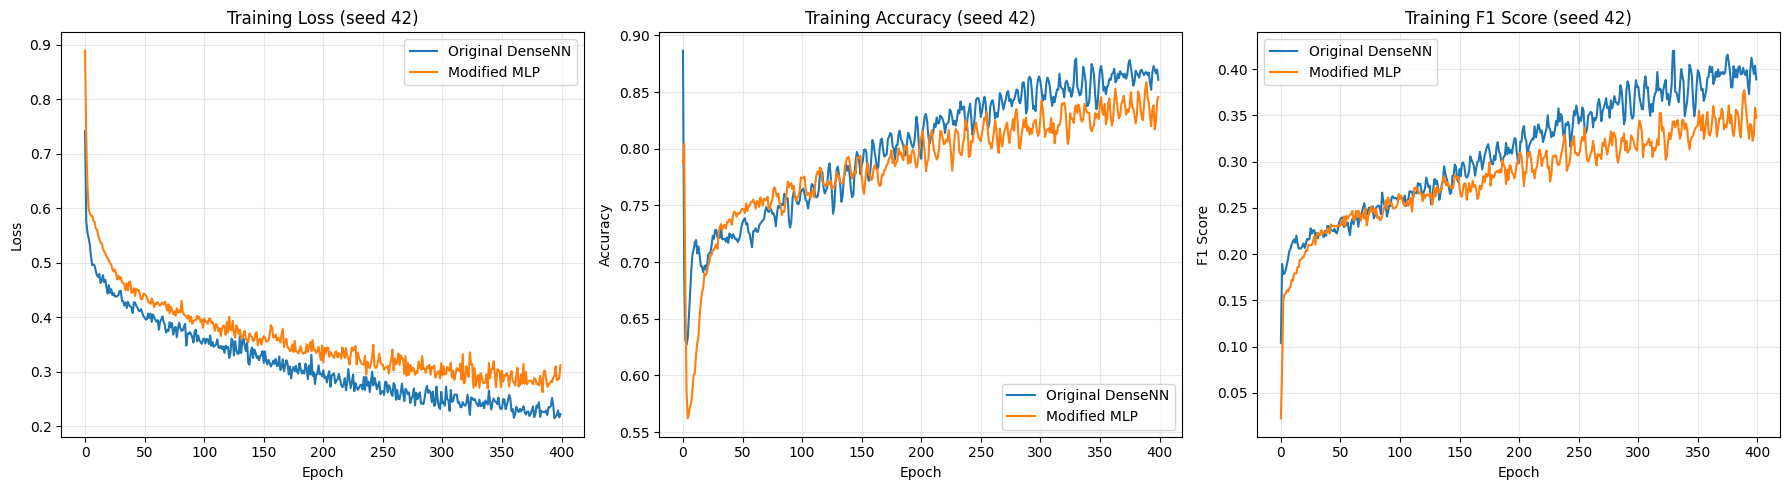

In [18]:
#================
# Training curves (first seed): original vs. modified
#================
seed0 = FINAL_SEEDS[0]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for name in runs:
    h = runs[name][seed0]["history"]
    axes[0].plot(h["train_loss"], label=name)
    axes[1].plot(h["train_accuracy"], label=name)
    axes[2].plot(h["train_f1"], label=name)

for ax, title, ylabel in zip(axes, ["Training Loss", "Training Accuracy", "Training F1 Score"],
                             ["Loss", "Accuracy", "F1 Score"]):
    ax.set_title(f"{title} (seed {seed0})")
    ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel)
    ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Final Test Evaluation (single use of the stroke test set)

In [19]:
#================
# Final evaluation: same metrics as the paper (+ ROC-AUC as a threshold-independent extra)
#================
y_true = y_test_tensor.numpy()

preds, probs = {}, {}
for name in runs:
    preds[name], probs[name] = {}, {}
    for seed in FINAL_SEEDS:
        preds[name][seed], probs[name][seed] = predict(runs[name][seed]["net"], X_test_tensor)


def run_metrics(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
    }


per_seed_df = pd.DataFrame([
    {"Model": name, "Seed": seed, **run_metrics(y_true, preds[name][seed], probs[name][seed])}
    for name in runs for seed in FINAL_SEEDS
])
print("Per-seed test metrics")
display(per_seed_df.round(4))

metric_names = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
summary_rows = []
for name in runs:
    sub = per_seed_df[per_seed_df["Model"] == name]
    row = {"Model": name, "Parameters": count_params(runs[name][seed0]["net"])}
    for m in metric_names:
        row[m] = f"{sub[m].mean():.4f} ± {sub[m].std(ddof=0):.4f}"
    summary_rows.append(row)

print("\nSTROKE DATASET: TEST RESULTS (mean ± std over 3 seeds, argmax decision)")
print("=" * 70)
display(pd.DataFrame(summary_rows))
pd.DataFrame(summary_rows).to_csv("stroke_bonus_results_summary.csv", index=False)

# Sanity check: original model with seed 42 should reproduce the paper's run above
if "metrics" in globals():
    ours = per_seed_df[(per_seed_df["Model"] == "Original DenseNN") & (per_seed_df["Seed"] == 42)].iloc[0]
    print("\nReproduction check (Original DenseNN, seed 42 vs. paper's reported run):")
    for key_paper, key_ours in [("accuracy", "Accuracy"), ("precision", "Precision"),
                                ("recall", "Recall"), ("f1_score", "F1-score")]:
        print(f"  {key_ours:10s} paper {metrics[key_paper]:.4f} | here {ours[key_ours]:.4f}")

Per-seed test metrics


,Model,Seed,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Original DenseNN,42,0.8571,0.2042,0.4677,0.2843,0.7924
1,Original DenseNN,123,0.8523,0.1888,0.4355,0.2634,0.7968
2,Original DenseNN,2024,0.8718,0.2101,0.4032,0.2762,0.7965
3,Modified MLP,42,0.8493,0.1892,0.4516,0.2667,0.7832
4,Modified MLP,123,0.8454,0.1667,0.3871,0.2330,0.7648
5,Modified MLP,2024,0.8288,0.1771,0.5000,0.2616,0.7891



STROKE DATASET: TEST RESULTS (mean ± std over 3 seeds, argmax decision)


,Model,Parameters,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Original DenseNN,12258,0.8604 ± 0.0083,0.2010 ± 0.0090,0.4355 ± 0.0263,0.2747 ± 0.0086,0.7952 ± 0.0020
1,Modified MLP,1010,0.8412 ± 0.0089,0.1777 ± 0.0092,0.4462 ± 0.0462,0.2538 ± 0.0148,0.7791 ± 0.0103



Reproduction check (Original DenseNN, seed 42 vs. paper's reported run):
  Accuracy   paper 0.8571 | here 0.8571
  Precision  paper 0.2042 | here 0.2042
  Recall     paper 0.4677 | here 0.4677
  F1-score   paper 0.2843 | here 0.2843



Original DenseNN (seed 42)
               precision    recall  f1-score   support

No Stroke (0)     0.9625    0.8823    0.9207       960
   Stroke (1)     0.2042    0.4677    0.2843        62

     accuracy                         0.8571      1022
    macro avg     0.5834    0.6750    0.6025      1022
 weighted avg     0.9165    0.8571    0.8820      1022


Modified MLP (seed 42)
               precision    recall  f1-score   support

No Stroke (0)     0.9611    0.8750    0.9160       960
   Stroke (1)     0.1892    0.4516    0.2667        62

     accuracy                         0.8493      1022
    macro avg     0.5751    0.6633    0.5913      1022
 weighted avg     0.9143    0.8493    0.8766      1022



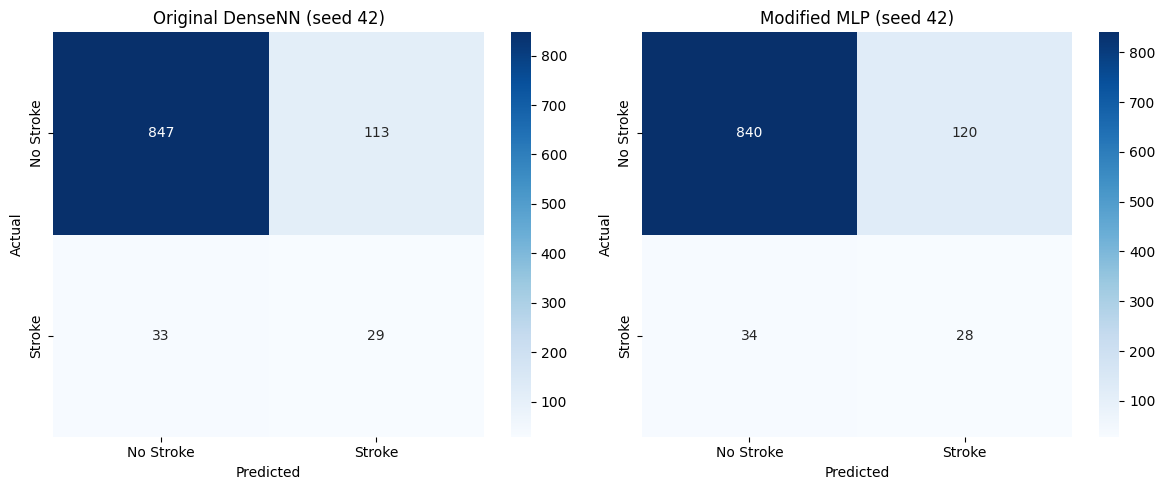

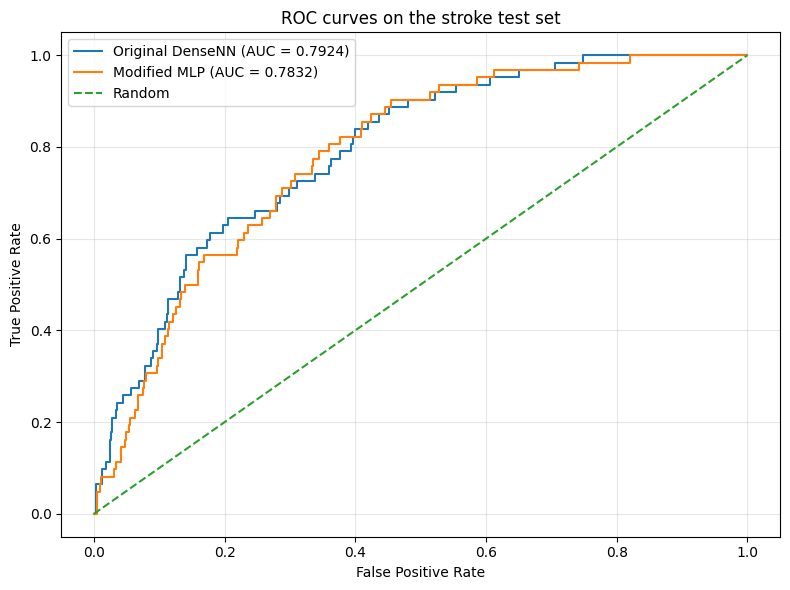

In [20]:
#================
# Per-class report, confusion matrices and ROC curves (first seed)
#================
for name in runs:
    print(f"\n{name} (seed {seed0})")
    print(classification_report(y_true, preds[name][seed0],
                                target_names=["No Stroke (0)", "Stroke (1)"], digits=4, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name in zip(axes, runs):
    cm = confusion_matrix(y_true, preds[name][seed0])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["No Stroke", "Stroke"], yticklabels=["No Stroke", "Stroke"])
    ax.set_title(f"{name} (seed {seed0})")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
for name in runs:
    fpr, tpr, _ = roc_curve(y_true, probs[name][seed0])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_true, probs[name][seed0]):.4f})")
plt.plot([0, 1], [0, 1], "--", label="Random")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC curves on the stroke test set")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
#================
# Is the difference real? Paired bootstrap on the test set (3-seed averages)
#================
rng = np.random.RandomState(123)
n_test = len(y_true)
N_BOOT = 1000
boot_metrics = ["Accuracy", "F1-score", "ROC-AUC"]
diffs = {m: [] for m in boot_metrics}

for _ in range(N_BOOT):
    idx = rng.randint(0, n_test, n_test)
    yt = y_true[idx]
    if yt.min() == yt.max():
        continue
    res = {}
    for name in runs:
        vals = [run_metrics(yt, preds[name][s][idx], probs[name][s][idx]) for s in FINAL_SEEDS]
        res[name] = {m: np.mean([v[m] for v in vals]) for m in boot_metrics}
    for m in boot_metrics:
        diffs[m].append(res["Modified MLP"][m] - res["Original DenseNN"][m])

boot_rows = []
for m, d in diffs.items():
    lo, hi = np.percentile(d, [2.5, 97.5])
    boot_rows.append({"Metric": m, "Mean difference (Modified − Original)": np.mean(d),
                      "95% CI low": lo, "95% CI high": hi,
                      "Distinguishable from 0?": "yes" if (lo > 0 or hi < 0) else "no"})
display(pd.DataFrame(boot_rows).round(4))

,Metric,Mean difference (Modified − Original),95% CI low,95% CI high,Distinguishable from 0?
0,Accuracy,-0.0192,-0.0303,-0.0085,yes
1,F1-score,-0.0206,-0.0586,0.0188,no
2,ROC-AUC,-0.0159,-0.0339,0.0024,no


## Discussion

**How to read these results.** The stroke data is small (5,110 patients) and highly imbalanced (about 4.6% positives; the test split has only 62 stroke cases out of 1,022). Two consequences matter for interpretation:

* **Accuracy is dominated by the majority class.** Always predicting "No Stroke" already gives about 93.9% test accuracy, so the paper's own run (≈ 0.86 accuracy) is *below* that trivial baseline. This is the expected effect of the class-weighted loss, which trades accuracy for recall on the minority class. Compare models on **recall, precision, F1 of the stroke class and ROC-AUC**, not on accuracy alone.
* **With 62 positives, test metrics are noisy.** A single additional correct or wrong stroke prediction shifts recall by about 1.6 points. This is why the paired bootstrap and the 3-seed spread are reported; differences inside the confidence interval should not be presented as improvements.

**What this experiment isolates.** Training data, preprocessing, split, loss (including class weights), optimiser, learning rate and epoch count are the paper's. Only the architecture differs (about 12k → about 1k parameters). The architecture was chosen on the cardiovascular validation set and was **not tuned on the stroke data**, so any difference (better, equal or worse) is a genuine transfer result, not an artefact of test-set selection.

**Conclusion guidance.**
* If the bootstrap intervals for F1 and ROC-AUC include zero, the honest conclusion is that the modified architecture performs **comparably** to the paper's with roughly 12× fewer parameters; it does not beat the paper.
* Only if an interval excludes zero in the favourable direction should the report claim that the modified model outperforms the original on the paper's dataset, and then with the size of the effect and its interval.
* If the modified model is worse on the stroke data, that is also a valid and informative result: the architecture selected for the (balanced, larger) cardiovascular data does not automatically transfer to a small, heavily imbalanced dataset.

**Limitations.** Single fixed split (the paper's), 62 test positives, 3 seeds, and no validation set in the paper's protocol (so no early stopping or tuning could be applied without changing the pipeline).